## Import Libraries Below

Here are all the imported libraries needed to do the full data analysis below:


In [11]:
import numpy as np              # numbers, arrays, math
import pandas as pd             # tables, csv loading, data handling
import os                       # file and path utilities

from sklearn.tree import DecisionTreeClassifier       # decision tree model
from sklearn.ensemble import RandomForestClassifier   # random forest model
from sklearn.linear_model import LogisticRegression   # logistic regression model

from sklearn.model_selection import train_test_split  # split into train and test sets
from sklearn.model_selection import cross_val_score   # cross validation scoring

from sklearn.metrics import accuracy_score            # accuracy metric
from sklearn.metrics import classification_report     # precision, recall, f1 summary
from sklearn.metrics import confusion_matrix          # confusion matrix
from sklearn.metrics import roc_auc_score             # roc-auc score

import matplotlib.pyplot as plt   # plotting
import seaborn as sns             # nicer plots and heatmaps

import statsmodels.api as sm      # statistical models and summaries

import shap                       # shap values for model explainability

from sklearn.preprocessing import StandardScaler      # standardize continuous features
from sklearn.preprocessing import LabelEncoder        # encode class labels into numbers

from sklearn.inspection import permutation_importance # model-agnostic feature importance
#note: micromamba activate data_science_foundation to pip install and resolve shap issues

---

## EDA Assessments

### Loading Data
Adopted from HW 3-4

In [15]:
#making a function to load the data (from HW 03)

#prompt the input for file path then load the data
def load_data():
    try:
        folder_name = input("Enter the folder path: ") #copy the path of the folder (right clicked data folder and copy path)
        file_list = [f for f in os.listdir(folder_name) if f.endswith('.csv')] #searches files with csv extension in that folder
        print(f"Files found in {folder_name}: {file_list}") #lists all matching files
        
        for file in file_list: #tries to load each file into each variable separately
            var_name = os.path.splitext(file)[0]  #'customers' from 'customers.csv' for example
            globals()[var_name] = pd.read_csv(os.path.join(folder_name, file)) #set each file name as a variable
            print(f"Loaded {file} as variable '{var_name}'")
            
    except FileNotFoundError: #error handling
        print(f"Folder '{folder_name}' not found.")
        return None
    except Exception as e:
        print(f"Error loading data: {e}")
        return None
    return True 

#calling the function (copy data folder entire path into the prompt box)
load_data()

Files found in /Users/matthewthompson/Documents/Academics/DS Masters Academics/Data Mining and Discovery/Assignments/final-project-thompson/data: ['family_related_data.csv', 'animals_rateof_evolution.csv']
Loaded family_related_data.csv as variable 'family_related_data'
Loaded animals_rateof_evolution.csv as variable 'animals_rateof_evolution'


True

In [16]:
family_df = family_related_data
evolution_df = animals_rateof_evolution

In [17]:
print(family_df.info())

print(evolution_df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1087 entries, 0 to 1086
Data columns (total 13 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   Tree_Label  1087 non-null   object
 1   Phylum      1087 non-null   object
 2   SS          1087 non-null   int64 
 3   A           1087 non-null   int64 
 4   G           1087 non-null   int64 
 5   O           1087 non-null   int64 
 6   T           1087 non-null   int64 
 7   V           1087 non-null   int64 
 8   C           1087 non-null   int64 
 9   F           1087 non-null   int64 
 10  K           1087 non-null   int64 
 11  M           1087 non-null   int64 
 12  S           1087 non-null   int64 
dtypes: int64(11), object(2)
memory usage: 110.5+ KB
None
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 84 entries, 0 to 83
Data columns (total 12 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Tree    84 non-null     int64  
 1   Phylum  84 non-n

First DataFrame (family dataset)
This dataset has 1,087 rows and 13 columns, containing tree labels, phylum information, and 11 integer-coded traits (SS, A, G, …, S). It’s relatively large and purely categorical/numeric without missing values.

Second DataFrame (evolution dataset)
This dataset is much smaller with 84 rows and 12 columns, including phylum and trait averages stored as floats. It provides summarized trait-level values per tree, making it more compact and aggregated than the first.

##### Family_df below:

In [ ]:
###### SHAPE AND INFO

#choose dataset
df1 = family_df.copy()
dataset_name = "family_df"

# quick overview
print(f"\n=== {dataset_name} EDA ===")
print(f"Shape: {df1.shape[0]} rows × {df1.shape[1]} columns")
print("\nColumns:", list(df1.columns))
print("\nDtypes:\n", df1.dtypes)

# pick likely target + trait columns
all_traits = ['SS','A','G','O','T','V','C','F','K','M','S']
traits_present = [c for c in all_traits if c in df1.columns]
target_col = 'Phylum' if 'Phylum' in df1.columns else None
id_cols = [c for c in ['Tree_Label'] if c in df1.columns]

print("\nTarget column:", target_col)
print("Trait columns:", traits_present)
print("ID columns:", id_cols)



=== family_df EDA ===
Shape: 1087 rows × 13 columns

Columns: ['Tree_Label', 'Phylum', 'SS', 'A', 'G', 'O', 'T', 'V', 'C', 'F', 'K', 'M', 'S']

Dtypes:
 Tree_Label    object
Phylum        object
SS             int64
A              int64
G              int64
O              int64
T              int64
V              int64
C              int64
F              int64
K              int64
M              int64
S              int64
dtype: object

Target column: Phylum
Trait columns: ['SS', 'A', 'G', 'O', 'T', 'V', 'C', 'F', 'K', 'M', 'S']
ID columns: ['Tree_Label']


The family_df dataset has 1,087 rows and 13 columns, where Phylum is the categorical target, 11 numeric trait columns (SS–S) are features, and Tree_Label acts as an identifier. This makes it well-structured for classification tasks predicting phylum from trait patterns.

In [19]:
##### SUMMARY INFO 
# numeric & categorical summaries
numeric_df = df1.select_dtypes(include='number')
cat_df = df1.select_dtypes(include=['object','category'])

if not numeric_df.empty:
    print("\nSummary (numeric):\n", numeric_df.describe().T)
else:
    print("\nNo numeric columns for numeric summary.")

if not cat_df.empty:
    print("\nSummary (categorical):\n", cat_df.describe().T)
else:
    print("\nNo categorical columns for categorical summary.")



Summary (numeric):
      count      mean       std  min  25%  50%  75%  max
SS  1087.0  0.269549  0.443930  0.0  0.0  0.0  1.0  1.0
A   1087.0  0.037718  0.190602  0.0  0.0  0.0  0.0  1.0
G   1087.0  0.021159  0.143981  0.0  0.0  0.0  0.0  1.0
O   1087.0  0.103036  0.304146  0.0  0.0  0.0  0.0  1.0
T   1087.0  0.131555  0.338162  0.0  0.0  0.0  0.0  1.0
V   1087.0  0.093836  0.291735  0.0  0.0  0.0  0.0  1.0
C   1087.0  0.109476  0.312379  0.0  0.0  0.0  0.0  1.0
F   1087.0  0.181233  0.385388  0.0  0.0  0.0  0.0  1.0
K   1087.0  0.007360  0.085512  0.0  0.0  0.0  0.0  1.0
M   1087.0  0.107636  0.310062  0.0  0.0  0.0  0.0  1.0
S   1087.0  0.015639  0.124133  0.0  0.0  0.0  0.0  1.0

Summary (categorical):
            count unique          top freq
Tree_Label  1087   1087    1Laevipil    1
Phylum      1087     29  Arthropoda   917


The numeric traits are mostly binary (0/1) with low mean values, showing that most traits are absent in most samples, except SS (27%) and F (18%), which occur more frequently. Categorical data shows each Tree_Label is unique, and the dataset is highly imbalanced, with Arthropoda dominating (917 of 1087, ~84%) among the 29 phyla.

In [20]:
# missing values
na = df1.isna().sum()
na = na[na > 0]
if na.empty:
    print("\nNo missing values detected.")
else:
    print("\nColumns with nulls:\n", na)
    print("\nNull %:\n", (na/len(df)*100).round(2))


No missing values detected.


In [21]:
# unique counts
print("\nUnique values per column:\n", df1.nunique())


Unique values per column:
 Tree_Label    1087
Phylum          29
SS               2
A                2
G                2
O                2
T                2
V                2
C                2
F                2
K                2
M                2
S                2
dtype: int64


There are 29 unique phylum categories, while the other columns only have two unique values each, meaning they act like simple yes/no indicators for traits.

In [23]:
# outlier scan (IQR) – skip pure binary columns
from math import isfinite
print("\nOutlier scan (IQR):")
for col in numeric_df.columns:
    vals = df1[col].dropna().unique()
    # treat as binary if values subset of {0,1}
    if set(vals).issubset({0,1,0.0,1.0}):
        print(f"{col}: skipped (binary)")
        continue
    Q1 = df1[col].quantile(0.25)
    Q3 = df1[col].quantile(0.75)
    IQR = Q3 - Q1
    lo = Q1 - 1.5*IQR
    hi = Q3 + 1.5*IQR
    mask = (df1[col] < lo) | (df[col] > hi)
    cnt = int(mask.sum())
    pct = 100*cnt/len(df)
    print(f"{col}: {cnt} outliers ({pct:.2f}%)")



Outlier scan (IQR):
SS: skipped (binary)
A: skipped (binary)
G: skipped (binary)
O: skipped (binary)
T: skipped (binary)
V: skipped (binary)
C: skipped (binary)
F: skipped (binary)
K: skipped (binary)
M: skipped (binary)
S: skipped (binary)


Since all trait columns are binary (0/1), an IQR-based outlier scan is not applicable — there are no true numeric outliers in this dataset. The traits can only vary by presence/absence, not by extreme values

In [24]:
# skewness & kurtosis (continuous)
if not numeric_df.empty:
    with np.errstate(all='ignore'):
        print("\nSkewness:\n", numeric_df.drop(columns=id_cols, errors='ignore').skew(numeric_only=True))
        print("\nKurtosis:\n", numeric_df.drop(columns=id_cols, errors='ignore').kurt(numeric_only=True))
else:
    print("\nNo numeric columns for skew/kurtosis.")



Skewness:
 SS     1.040144
A      4.859686
G      6.663708
O      2.615167
T      2.183124
V      2.789603
C      2.504935
F      1.657315
K     11.543399
M      2.535538
S      7.818293
dtype: float64

Kurtosis:
 SS     -0.919795
A      21.656394
G      42.483164
O       4.848015
T       2.771127
V       5.792541
C       4.282576
F       0.748066
K     131.491989
M       4.437115
S      59.234697
dtype: float64


All traits are positively skewed, showing that “1” values are rare compared to “0”, with especially strong skew for K, S, and G. The very high kurtosis values (e.g., K = 131, S = 59) confirm that most traits are extremely concentrated near 0 with occasional 1s, reflecting strong sparsity in the dataset.All traits are positively skewed, meaning trait presence (1) is rare compared to absence (0). The strongest skew and highest kurtosis occur in K (female-female competition), S (intersexual conflict), and G (gustatory), showing these traits are extremely sparse, while more common traits like SS (any sexually selected trait) and F (female choice) are less skewed.

In [25]:
# correlations (absolute) among numeric
if not numeric_df.empty:
    corr = numeric_df.corr().abs()
    print("\nCorrelation matrix (|r|):\n", corr)

    # print per-column correlations ≥ 0.10
    print("\nCorrelations (|r| ≥ 0.10):")
    for col in corr.columns:
        s = corr[col].drop(labels=[col])
        s = s[s >= 0.10].sort_values(ascending=False)
        if s.empty:
            print(f"{col}: none ≥ 0.10")
        else:
            print(f"\n{col}:\n{s}")
else:
    print("\nNo numeric columns for correlation analysis.")



Correlation matrix (|r|):
           SS         A         G         O         T         V         C  \
SS  1.000000  0.315031  0.242030  0.551115  0.634572  0.529735  0.577181   
A   0.315031  1.000000  0.138659  0.107623  0.051520  0.135007  0.100703   
G   0.242030  0.138659  1.000000  0.097360  0.056249  0.128062  0.010604   
O   0.551115  0.107623  0.097360  1.000000  0.100862  0.119243  0.123462   
T   0.634572  0.051520  0.056249  0.100862  1.000000  0.294774  0.639344   
V   0.529735  0.135007  0.128062  0.119243  0.294774  1.000000  0.453005   
C   0.577181  0.100703  0.010604  0.123462  0.639344  0.453005  1.000000   
F   0.763723  0.370670  0.295909  0.539708  0.375067  0.438281  0.202182   
K   0.141746  0.039448  0.012660  0.041626  0.157547  0.119935  0.211111   
M   0.571720  0.274021  0.134572  0.722016  0.137071  0.163090  0.039847   
S   0.207496  0.052882  0.136029  0.054837  0.258047  0.061146  0.027045   

           F         K         M         S  
SS  0.763723  

The strongest associations are SS–F (0.76), O–M (0.72), T–C (0.64), and SS–T (0.63), showing that combined sexually selected traits strongly co-occur with female choice, and olfactory traits with male choice. Visual (V), tactile (T), and male–male competition (C) also form a moderately correlated cluster, while weaker links (e.g., K and S) indicate that female–female competition and intersexual conflict occur largely independently of other traits

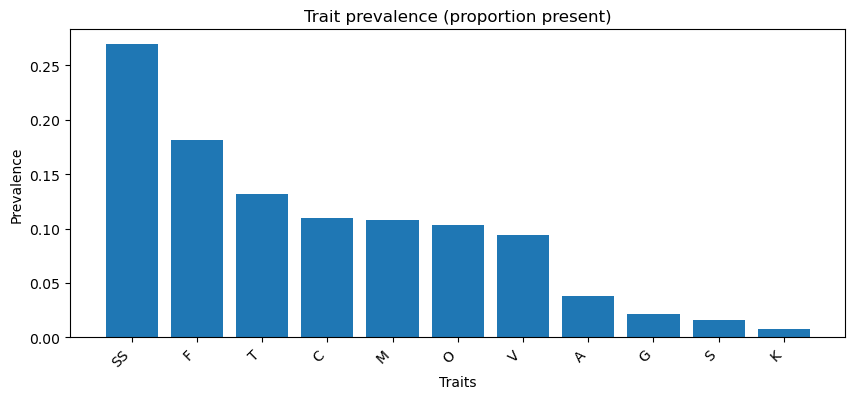

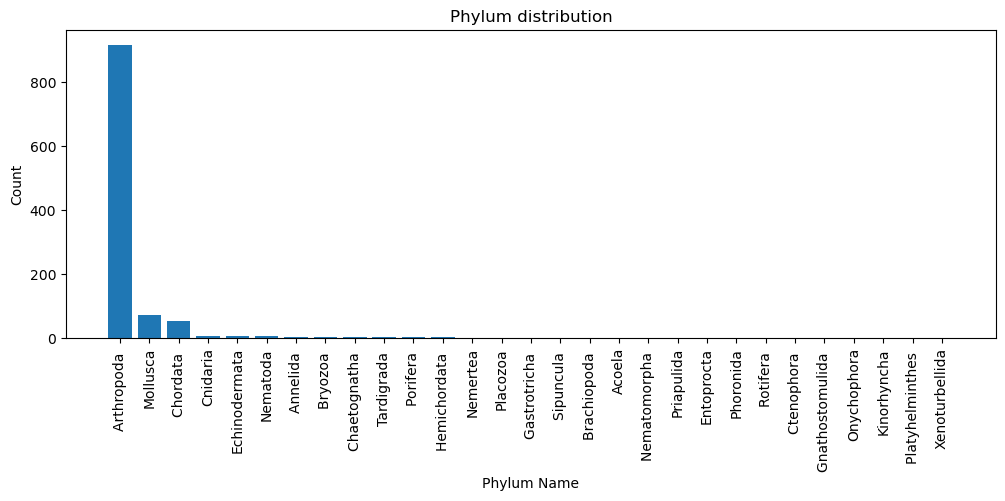

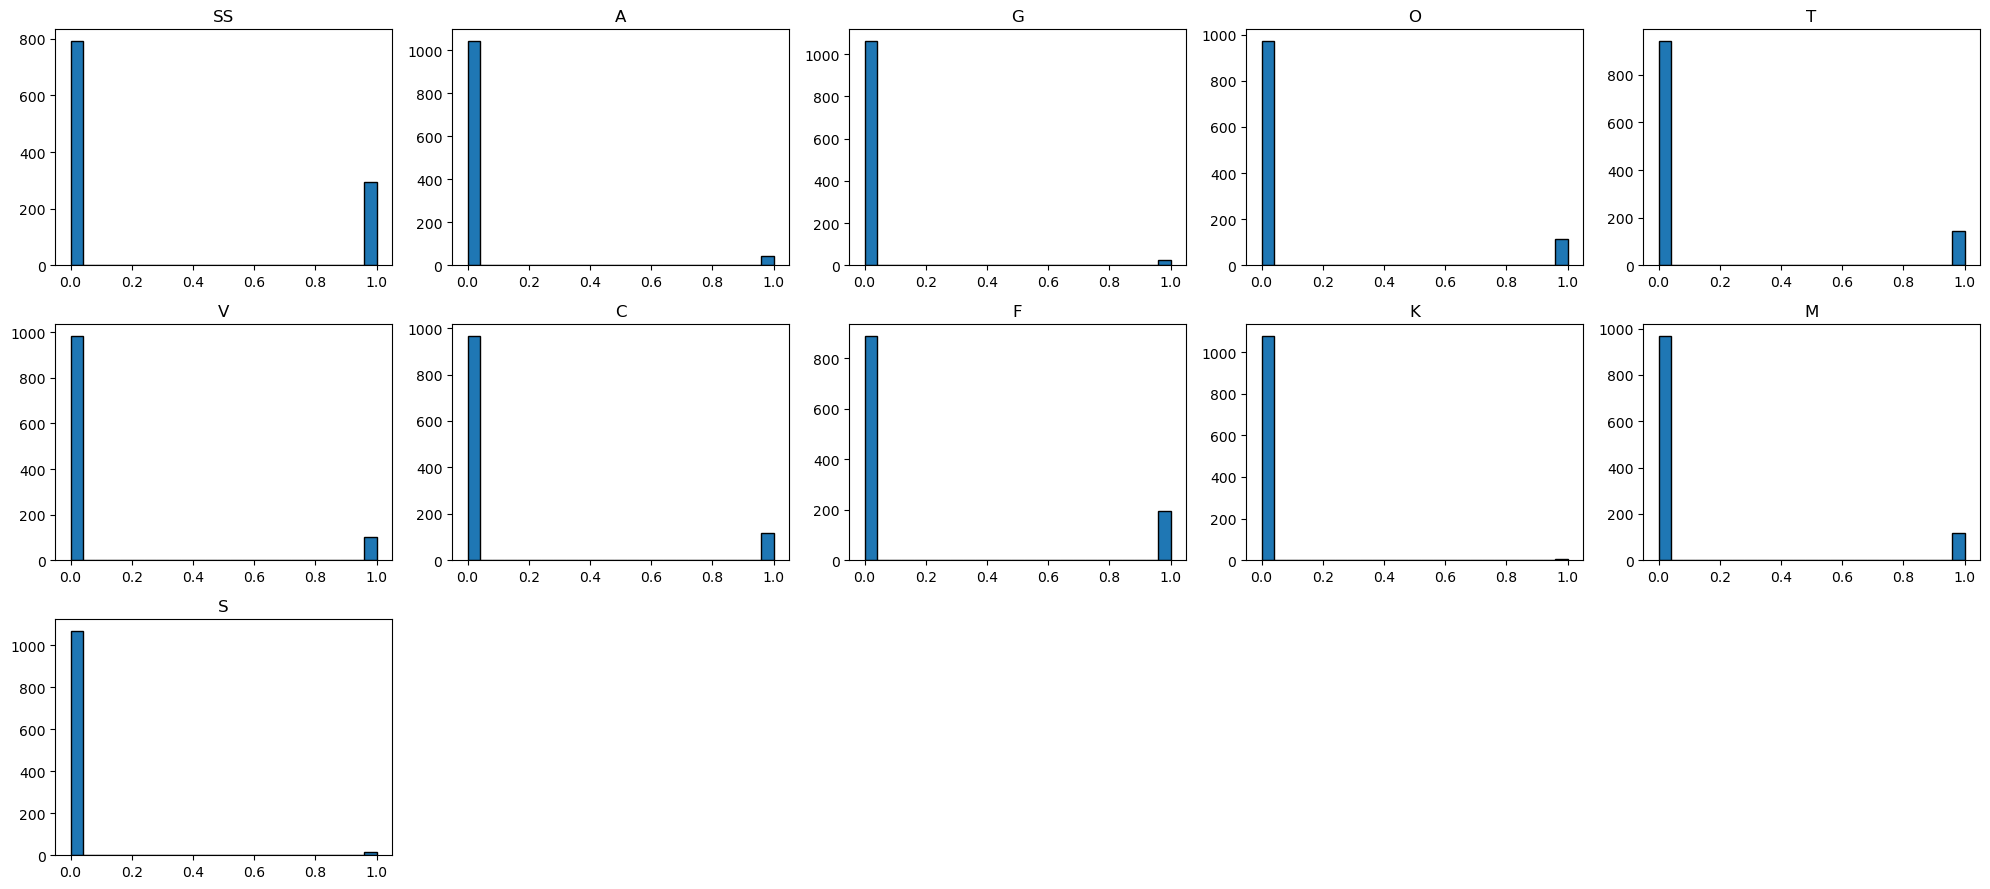

In [30]:
# plots – trait prevalence, phylum distribution, histograms (binary will show as 0/1 counts)

# 1) prevalence of binary traits
if traits_present:
    prev = df1[traits_present].mean().sort_values(ascending=False)
    plt.figure(figsize=(10,4))
    plt.bar(prev.index, prev.values)
    plt.title("Trait prevalence (proportion present)")
    plt.ylabel("Prevalence")
    plt.xlabel("Traits")
    plt.xticks(rotation=45, ha='right')
    plt.show()

# 2) phylum distribution
if target_col:
    counts = df1[target_col].value_counts()
    plt.figure(figsize=(12,4))
    plt.bar(counts.index, counts.values)
    plt.title(f"{target_col} distribution")
    plt.ylabel("Count")
    plt.xlabel("Phylum Name")
    plt.xticks(rotation=90)
    plt.show()

# 3) histograms for numeric (binary will appear as spikes at 0/1)
num_cols_list = list(numeric_df.columns)
if num_cols_list:
    n = len(num_cols_list)
    ncols = min(5, n)
    nrows = (n + ncols - 1) // ncols
    fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(4*ncols, 3*nrows))
    axes = np.array(axes).reshape(-1) if isinstance(axes, np.ndarray) else [axes]
    for i, col in enumerate(num_cols_list):
        ax = axes[i]
        ax.hist(df1[col].dropna(), bins=25, edgecolor="black")
        ax.set_title(col)
    for ax in axes[n:]:
        ax.axis('off')
    plt.tight_layout()
    plt.show()
else:
    print("\nNo numeric columns to plot.")



Trait prevalence by phylum (proportion present):
                      SS      A      G      O      T      V      C     F  \
Phylum                                                                    
Acoela            0.000  0.000  0.000  0.000  0.000  0.000  0.000  0.00   
Annelida          0.500  0.000  0.000  0.500  0.500  0.000  0.250  0.25   
Arthropoda        0.296  0.037  0.025  0.115  0.149  0.098  0.115  0.20   
Brachiopoda       0.000  0.000  0.000  0.000  0.000  0.000  0.000  0.00   
Bryozoa           0.000  0.000  0.000  0.000  0.000  0.000  0.000  0.00   
Chaetognatha      0.000  0.000  0.000  0.000  0.000  0.000  0.000  0.00   
Chordata          0.346  0.135  0.000  0.077  0.077  0.212  0.231  0.25   
Cnidaria          0.000  0.000  0.000  0.000  0.000  0.000  0.000  0.00   
Ctenophora        0.000  0.000  0.000  0.000  0.000  0.000  0.000  0.00   
Echinodermata     0.000  0.000  0.000  0.000  0.000  0.000  0.000  0.00   
Entoprocta        0.000  0.000  0.000  0.000  0.0

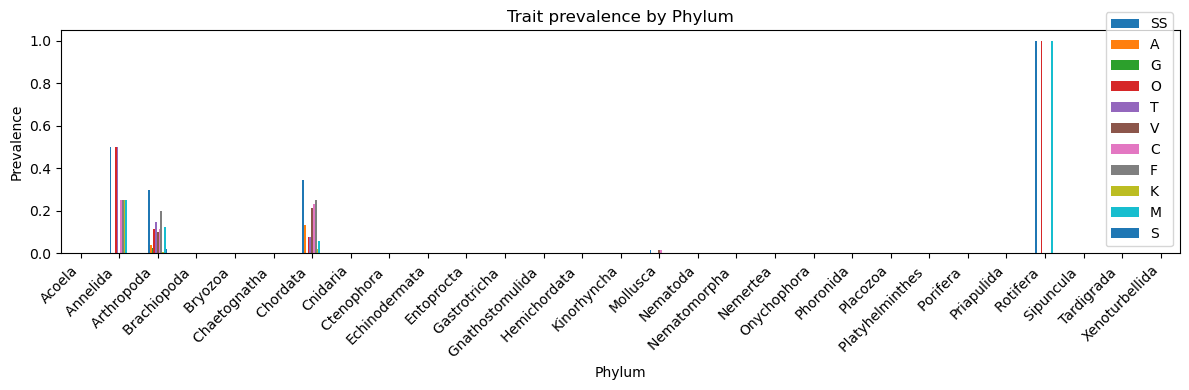

In [28]:
# traits by phylum (prevalence), if target exists
if target_col and traits_present:
    group_prev = df1.groupby(target_col)[traits_present].mean().sort_index()
    print("\nTrait prevalence by phylum (proportion present):\n", group_prev.round(3))

    # optional barplot per trait aggregated (wide)
    ax = group_prev.plot(kind='bar', figsize=(12, max(4, 0.35*len(group_prev.columns))))
    ax.set_title(f"Trait prevalence by {target_col}")
    ax.set_ylabel("Prevalence")
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()

Trait prevalence – The most common trait is SS (any sexually selected trait, ~27%), followed by F (female choice, ~18%) and T (tactile, ~13%), while traits like K (female–female competition), S (intersexual conflict), and G (gustatory) are rare (<3%).

Phylum distribution – The dataset is highly imbalanced, with Arthropoda dominating (~84%), while Mollusca and Chordata make up smaller fractions, and most other phyla have very few samples.

Trait histograms – All traits are binary with strong skew toward 0 (absence), confirming sparsity and explaining the high skewness/kurtosis values.

Trait prevalence by phylum – Certain phyla (e.g., Arthropoda, Chordata, Annelida) show meaningful diversity of trait presence, while most phyla exhibit almost no sexually selected traits in the dataset.

##### Evolution df below:

In [31]:
df2 = evolution_df.copy()

# quick overview
print(f"\n=== df2 EDA (evolution_df) ===")
print(f"Shape: {df2.shape[0]} rows × {df2.shape[1]} columns")
print("\nColumns:", list(df2.columns))
print("\nDtypes:\n", df2.dtypes)

# target and trait columns
all_traits = ['A','G','O','T','V','C','F','K','M','S']  # continuous traits
traits_present = [c for c in all_traits if c in df2.columns]
target_col = 'Phylum' if 'Phylum' in df2.columns else None
id_cols = [c for c in ['Tree'] if c in df2.columns]

print("\nTarget column:", target_col)
print("Trait columns:", traits_present)
print("ID columns:", id_cols)



=== df2 EDA (evolution_df) ===
Shape: 84 rows × 12 columns

Columns: ['Tree', 'Phylum', 'A', 'G', 'O', 'T', 'V', 'C', 'F', 'K', 'M', 'S']

Dtypes:
 Tree        int64
Phylum     object
A         float64
G         float64
O         float64
T         float64
V         float64
C         float64
F         float64
K         float64
M         float64
S         float64
dtype: object

Target column: Phylum
Trait columns: ['A', 'G', 'O', 'T', 'V', 'C', 'F', 'K', 'M', 'S']
ID columns: ['Tree']


#### Overall Key Insights

**Family**
- Dataset structure: The dataset has 1,087 rows × 13 columns, with Phylum as the categorical target, 11 binary-coded sexually selected traits (SS–S) as predictors, and Tree_Label as a unique ID.
- Severe class imbalance: The Arthropoda phylum dominates (~84%), while Mollusca (~8%) and Chordata (~5%) are minor classes, and most other phyla have only a handful of samples. This imbalance will strongly affect classification performance.
- Trait prevalence patterns: Most traits are rare, with SS (any sexually selected trait, ~27%) and F (female choice, ~18%) being the most frequent. In contrast, K (female–female competition), S (intersexual conflict), and G (gustatory) appear in <3% of samples, meaning they contribute very sparse signals.
- Distribution shape: Because traits are binary and sparse, they show strong positive skew and extreme kurtosis, indicating most samples lack a given trait. This makes the dataset sparse and unbalanced at both feature and target levels.
- Correlation structure: Traits cluster into co-occurring groups:
- SS and F are very tightly linked (r ≈ 0.76),
- Olfactory (O) and Male choice (M) also correlate strongly (r ≈ 0.72),
- Tactile (T) and Male–male competition (C) pair closely (r ≈ 0.64).
- These clusters suggest certain evolutionary mechanisms tend to evolve together.
- By phylum trait diversity: Only a few phyla (Arthropoda, Chordata, Annelida) show meaningful variation in sexually selected traits. Most phyla have near-zero prevalence, meaning trait-driven classification will be heavily biased toward the larger groups.

